# SARIMAX Classical Forecasting Baseline

## Purpose

This notebook implements the frozen SARIMAX classical forecasting baseline for the SA1 and NSW1 AEMO half-hourly electricity-demand datasets.

The model is fitted using the fixed 2018–2019 Train data only. Demand standardisation is also calculated from Train only. The fitted parameters are frozen before Calibration and Test, and chronological one-step-ahead forecasts are produced without parameter re-estimation.

The required outputs are:

- prediction errors for every Test observation;
- MAE, RMSE and MAPE;
- trailing 7-day rolling MAE using 336 half-hourly errors;
- actual-demand versus forecast plots;
- SARIMAX degradation curves;
- detector-compatible chronological error streams;
- saved predictions, metrics, configuration and figures.


In [1]:
import sys
import time
import warnings

import matplotlib
import numpy as np
import pandas as pd
import statsmodels

from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", category=ConvergenceWarning)

print("Python executable:", sys.executable)
print("pandas version:", pd.__version__)
print("matplotlib version:", matplotlib.__version__)
print("statsmodels version:", statsmodels.__version__)

Python executable: /opt/anaconda3/bin/python
pandas version: 2.2.2
matplotlib version: 3.9.2
statsmodels version: 0.14.2


In [3]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt


current_directory = Path.cwd()

if (current_directory / "src").exists():
    project_root = current_directory
elif (current_directory.parent / "src").exists():
    project_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root containing the src folder."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_and_split_aemo

data_path = project_root / "data" / "raw"
results_path = project_root / "results"
prediction_path = results_path / "predictions"
figure_path = results_path / "figures"
model_path = results_path / "forecasting_baselines"

prediction_path.mkdir(parents=True, exist_ok=True)
figure_path.mkdir(parents=True, exist_ok=True)
model_path.mkdir(parents=True, exist_ok=True)

print("Current directory:", current_directory)
print("Project root:", project_root)
print("Raw data path:", data_path)
print("Raw data path exists:", data_path.exists())

Current directory: /Users/fangziqi/Downloads/capstone porject/ConceptDriftProject/notebooks
Project root: /Users/fangziqi/Downloads/capstone porject/ConceptDriftProject
Raw data path: /Users/fangziqi/Downloads/capstone porject/ConceptDriftProject/data/raw
Raw data path exists: True


In [5]:
sa1_data, sa1_train, sa1_calibration, sa1_test = (
    load_and_split_aemo(
        region="SA1",
        data_path=data_path
    )
)

nsw1_data, nsw1_train, nsw1_calibration, nsw1_test = (
    load_and_split_aemo(
        region="NSW1",
        data_path=data_path
    )
)

print("SA1 loaded successfully.")
print("Full:", len(sa1_data))
print("Train:", len(sa1_train))
print("Calibration:", len(sa1_calibration))
print("Test:", len(sa1_test))

print()

print("NSW1 loaded successfully.")
print("Full:", len(nsw1_data))
print("Train:", len(nsw1_train))
print("Calibration:", len(nsw1_calibration))
print("Test:", len(nsw1_test))

SA1 loaded successfully.
Full: 105168
Train: 35039
Calibration: 2880
Test: 67249

NSW1 loaded successfully.
Full: 105168
Train: 35039
Calibration: 2880
Test: 67249


In [7]:
print("SA1 columns:", sa1_data.columns.tolist())
print(
    "SA1 date range:",
    sa1_data["SETTLEMENTDATE"].min(),
    "to",
    sa1_data["SETTLEMENTDATE"].max()
)

print()

print("NSW1 columns:", nsw1_data.columns.tolist())
print(
    "NSW1 date range:",
    nsw1_data["SETTLEMENTDATE"].min(),
    "to",
    nsw1_data["SETTLEMENTDATE"].max()
)

print("\nFirst five SA1 observations:")
display(sa1_data.head())

print("First five NSW1 observations:")
display(nsw1_data.head())

SA1 columns: ['SETTLEMENTDATE', 'TOTALDEMAND']
SA1 date range: 2018-01-01 00:30:00 to 2024-01-01 00:00:00

NSW1 columns: ['SETTLEMENTDATE', 'TOTALDEMAND']
NSW1 date range: 2018-01-01 00:30:00 to 2024-01-01 00:00:00

First five SA1 observations:


,SETTLEMENTDATE,TOTALDEMAND
0,2018-01-01 00:30:00,1289.10
1,2018-01-01 01:00:00,1242.28
2,2018-01-01 01:30:00,1156.19
3,2018-01-01 02:00:00,1112.46
4,2018-01-01 02:30:00,1094.20


First five NSW1 observations:


,SETTLEMENTDATE,TOTALDEMAND
0,2018-01-01 00:30:00,6912.25
1,2018-01-01 01:00:00,6745.63
2,2018-01-01 01:30:00,6466.06
3,2018-01-01 02:00:00,6279.80
4,2018-01-01 02:30:00,6177.31


In [9]:
def validate_aemo_data(data, region_name):
    required_columns = {
        "SETTLEMENTDATE",
        "TOTALDEMAND"
    }

    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(
            f"{region_name} is missing columns: {missing_columns}"
        )

    if not data["SETTLEMENTDATE"].is_monotonic_increasing:
        raise ValueError(
            f"{region_name} timestamps are not in chronological order."
        )

    if data["SETTLEMENTDATE"].duplicated().any():
        raise ValueError(
            f"{region_name} contains duplicated timestamps."
        )

    if data["TOTALDEMAND"].isna().any():
        raise ValueError(
            f"{region_name} contains missing demand values."
        )

    time_differences = (
        data["SETTLEMENTDATE"]
        .diff()
        .dropna()
    )

    if not (
        time_differences == pd.Timedelta(minutes=30)
    ).all():
        raise ValueError(
            f"{region_name} does not have a consistent 30-minute frequency."
        )

    print(f"{region_name} validation passed.")


validate_aemo_data(sa1_data, "SA1")
validate_aemo_data(nsw1_data, "NSW1")

timestamps_match = (
    sa1_data["SETTLEMENTDATE"]
    .reset_index(drop=True)
    .equals(
        nsw1_data["SETTLEMENTDATE"]
        .reset_index(drop=True)
    )
)

print("SA1 and NSW1 timestamps match:", timestamps_match)

SA1 validation passed.
NSW1 validation passed.
SA1 and NSW1 timestamps match: True


## Validation Utilities

These checks confirm that the forecast output is complete, chronological and compatible with the detector interface.


In [12]:
def validate_forecast_results(results, test_data, region_name):
    if len(results) != len(test_data):
        raise ValueError(
            f"{region_name}: result length does not match test length."
        )

    if results["prediction"].isna().any():
        raise ValueError(f"{region_name}: missing predictions were found.")

    if results["absolute_error"].isna().any():
        raise ValueError(f"{region_name}: missing absolute errors were found.")

    expected_initial_rolling_nan = (48 * 7) - 1
    actual_initial_rolling_nan = results["rolling_mae_7d"].isna().sum()
    if actual_initial_rolling_nan != expected_initial_rolling_nan:
        raise ValueError(
            f"{region_name}: unexpected number of initial rolling-MAE "
            "missing values."
        )

    if not results["SETTLEMENTDATE"].is_monotonic_increasing:
        raise ValueError(f"{region_name}: results are not chronological.")

    print(
        f"{region_name} forecast validation passed; "
        f"initial rolling-MAE NaNs={actual_initial_rolling_nan}."
    )


def validate_detector_stream(stream, region_name):
    if stream.ndim != 1:
        raise ValueError(
            f"{region_name}: error stream is not one-dimensional."
        )
    if not np.issubdtype(stream.dtype, np.number):
        raise ValueError(f"{region_name}: error stream is not numeric.")
    if not np.isfinite(stream).all():
        raise ValueError(
            f"{region_name}: error stream contains invalid values."
        )
    print(
        f"{region_name} detector stream passed: "
        f"length={len(stream):,}, dimensions={stream.ndim}, dtype={stream.dtype}."
    )


## SARIMAX Classical Baseline

SARIMAX is the single official classical baseline. Its configuration is
fixed before Calibration and Test. An AR(1) error model is combined with
deterministic daily, weekly and annual Fourier/calendar features. Only Train
observations are used for parameter estimation. Demand is standardised using
the Train mean and standard deviation to stabilise numerical optimisation;
forecasts are transformed back to MW before evaluation.

In [15]:
TIME_COLUMN = "SETTLEMENTDATE"
TARGET_COLUMN = "TOTALDEMAND"
POINTS_PER_DAY = 48
ROLLING_WINDOW = 7 * POINTS_PER_DAY
REGIONS = ["SA1", "NSW1"]

data_by_region = {
    "SA1": {"train": sa1_train, "calibration": sa1_calibration, "test": sa1_test},
    "NSW1": {"train": nsw1_train, "calibration": nsw1_calibration, "test": nsw1_test},
}

def to_demand_series(data):
    series = (
        data[[TIME_COLUMN, TARGET_COLUMN]]
        .set_index(TIME_COLUMN)[TARGET_COLUMN]
        .astype(float)
        .asfreq("30min")
    )
    if series.isna().any():
        raise ValueError("Demand series contains missing half-hour rows.")
    return series


def make_calendar_features(index):
    index = pd.DatetimeIndex(index)
    half_hour_slot = index.hour * 2 + (index.minute // 30)
    day_of_week = index.dayofweek
    week_slot = day_of_week * POINTS_PER_DAY + half_hour_slot
    day_of_year = index.dayofyear + half_hour_slot / POINTS_PER_DAY
    features = pd.DataFrame(index=index)

    for harmonic in (1, 2, 3):
        angle = 2 * np.pi * harmonic * half_hour_slot / POINTS_PER_DAY
        features[f"daily_sin_{harmonic}"] = np.sin(angle)
        features[f"daily_cos_{harmonic}"] = np.cos(angle)

    for harmonic in (1, 2):
        angle = 2 * np.pi * harmonic * week_slot / ROLLING_WINDOW
        features[f"weekly_sin_{harmonic}"] = np.sin(angle)
        features[f"weekly_cos_{harmonic}"] = np.cos(angle)

    annual_angle = 2 * np.pi * day_of_year / 365.25
    features["annual_sin_1"] = np.sin(annual_angle)
    features["annual_cos_1"] = np.cos(annual_angle)
    features["is_weekend"] = (day_of_week >= 5).astype(int)
    return features.astype(float)


SARIMAX_CONFIG = {
    "order": (1, 0, 0),
    "seasonal_order": (0, 0, 0, 0),
    "trend": "c",
}
print("Fixed SARIMAX configuration:", SARIMAX_CONFIG)

sarimax_models = {}
sarimax_parameter_snapshots = {}
sarimax_scalers = {}
sarimax_fit_rows = []

for region_name in REGIONS:
    train = to_demand_series(data_by_region[region_name]["train"])
    train_mean = float(train.mean())
    train_std = float(train.std())
    if not np.isfinite(train_std) or train_std <= 0:
        raise ValueError(f"{region_name}: invalid Train standard deviation.")
    train_scaled = (train - train_mean) / train_std
    sarimax_scalers[region_name] = {"mean": train_mean, "std": train_std}
    fit_start = time.perf_counter()
    print(
        f"Starting SARIMAX fit for {region_name} with "
        f"{len(train):,} Train observations...", flush=True
    )
    model = SARIMAX(
        endog=train_scaled,
        exog=make_calendar_features(train.index),
        order=SARIMAX_CONFIG["order"],
        seasonal_order=SARIMAX_CONFIG["seasonal_order"],
        trend=SARIMAX_CONFIG["trend"],
        enforce_stationarity=False,
        enforce_invertibility=True,
        concentrate_scale=False,
    )
    fitted = model.fit(
        method="lbfgs", disp=False, maxiter=200, cov_type="none"
    )
    converged = bool(fitted.mle_retvals.get("converged", False))

    if not converged:
        print(
            f"{region_name} did not converge with L-BFGS; "
            "trying Powell from the current estimate...", flush=True
        )
        fitted = model.fit(
            start_params=np.asarray(fitted.params),
            method="powell", disp=False, maxiter=200, cov_type="none"
        )
        converged = bool(fitted.mle_retvals.get("converged", False))

    if not converged:
        raise RuntimeError(
            f"{region_name}: SARIMAX did not converge. "
            "Do not use its forecasts as final results."
        )

    fit_seconds = time.perf_counter() - fit_start
    sarimax_models[region_name] = fitted
    sarimax_parameter_snapshots[region_name] = np.asarray(fitted.params).copy()
    sarimax_fit_rows.append({
        "region": region_name,
        "order": str(SARIMAX_CONFIG["order"]),
        "seasonal_order": str(SARIMAX_CONFIG["seasonal_order"]),
        "train_samples": len(train),
        "train_mean_mw": train_mean,
        "train_std_mw": train_std,
        "fit_wall_clock_s": fit_seconds,
        "converged": converged,
        "frozen_before_calibration_and_test": True,
    })
    print(
        f"Completed SARIMAX fit for {region_name} in "
        f"{fit_seconds:.1f} seconds; converged={converged}.", flush=True
    )

sarimax_configuration = pd.DataFrame(sarimax_fit_rows)
display(sarimax_configuration)

Fixed SARIMAX configuration: {'order': (1, 0, 0), 'seasonal_order': (0, 0, 0, 0), 'trend': 'c'}
Starting SARIMAX fit for SA1 with 35,039 Train observations...
Completed SARIMAX fit for SA1 in 22.3 seconds; converged=True.
Starting SARIMAX fit for NSW1 with 35,039 Train observations...
Completed SARIMAX fit for NSW1 in 26.6 seconds; converged=True.


,region,order,seasonal_order,train_samples,train_mean_mw,train_std_mw,fit_wall_clock_s,converged,frozen_before_calibration_and_test
0,SA1,"(1, 0, 0)","(0, 0, 0, 0)",35039,1300.873054,326.761899,22.334141,True,True
1,NSW1,"(1, 0, 0)","(0, 0, 0, 0)",35039,7982.251665,1218.387824,26.598525,True,True


## Frozen Calibration and Test Roll-Forward

Calibration advances the state-space filter without changing fitted
coefficients. Test forecasts are then produced chronologically with the same
frozen parameter vector.

In [17]:
sarimax_results = {}

for region_name in REGIONS:
    calibration_raw = to_demand_series(
        data_by_region[region_name]["calibration"]
    )
    test_raw = to_demand_series(data_by_region[region_name]["test"])
    train_mean = sarimax_scalers[region_name]["mean"]
    train_std = sarimax_scalers[region_name]["std"]
    calibration = (calibration_raw - train_mean) / train_std
    test = (test_raw - train_mean) / train_std
    fitted = sarimax_models[region_name]
    roll_start = time.perf_counter()
    print(
        f"Rolling frozen SARIMAX through Calibration and "
        f"{len(test):,} Test observations for {region_name}...", flush=True
    )
    calibration_state = fitted.extend(
        endog=calibration, exog=make_calendar_features(calibration.index)
    )
    test_state = calibration_state.extend(
        endog=test, exog=make_calendar_features(test.index)
    )
    np.testing.assert_allclose(
        sarimax_parameter_snapshots[region_name], np.asarray(test_state.params),
        rtol=1e-10, atol=1e-10
    )
    prediction_mw = (
        np.asarray(test_state.fittedvalues) * train_std + train_mean
    )
    results = pd.DataFrame({
        TIME_COLUMN: test_raw.index,
        TARGET_COLUMN: test_raw.to_numpy(),
        "prediction": prediction_mw,
    })
    results["error"] = results[TARGET_COLUMN] - results["prediction"]
    results["absolute_error"] = results["error"].abs()
    results["rolling_mae_7d"] = (
        results["absolute_error"]
        .rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW)
        .mean()
    )
    validate_forecast_results(
        results, data_by_region[region_name]["test"], f"{region_name} SARIMAX"
    )
    sarimax_results[region_name] = results
    print(
        f"Completed SARIMAX roll-forward for {region_name} in "
        f"{time.perf_counter() - roll_start:.1f} seconds.", flush=True
    )

print("Frozen SARIMAX parameter audit passed for both regions.")


def calculate_metrics(results, region_name, model_name):
    actual = results[TARGET_COLUMN]
    error = results["error"]
    absolute_error = results["absolute_error"]
    nonzero = actual.ne(0)
    return {
        "region": region_name, "model": model_name,
        "test_observations": len(results),
        "mae_mw": float(absolute_error.mean()),
        "rmse_mw": float(np.sqrt(np.mean(error ** 2))),
        "mape_percent": float(
            (absolute_error[nonzero] / actual[nonzero]).mean() * 100
        ),
        "missing_predictions": int(results["prediction"].isna().sum()),
        "test_stream_retrains": 0,
    }

metric_rows = [
    calculate_metrics(sarimax_results[region_name], region_name, "SARIMAX")
    for region_name in REGIONS
]
sarimax_metrics = pd.DataFrame(metric_rows)
display(sarimax_metrics)


Rolling frozen SARIMAX through Calibration and 67,249 Test observations for SA1...
SA1 SARIMAX forecast validation passed; initial rolling-MAE NaNs=335.
Completed SARIMAX roll-forward for SA1 in 0.3 seconds.
Rolling frozen SARIMAX through Calibration and 67,249 Test observations for NSW1...
NSW1 SARIMAX forecast validation passed; initial rolling-MAE NaNs=335.
Completed SARIMAX roll-forward for NSW1 in 0.3 seconds.
Frozen SARIMAX parameter audit passed for both regions.


,region,model,test_observations,mae_mw,rmse_mw,mape_percent,missing_predictions,test_stream_retrains
0,SA1,SARIMAX,67249,43.002970,60.824194,4.073120,0,0
1,NSW1,SARIMAX,67249,122.860421,172.409815,1.611979,0,0


## SARIMAX Forecasts and Degradation Curves

The degradation curve uses a trailing 7-day window of 336 half-hourly forecast errors. Event markers support later interpretation; variation in rolling MAE alone does not prove concept drift.


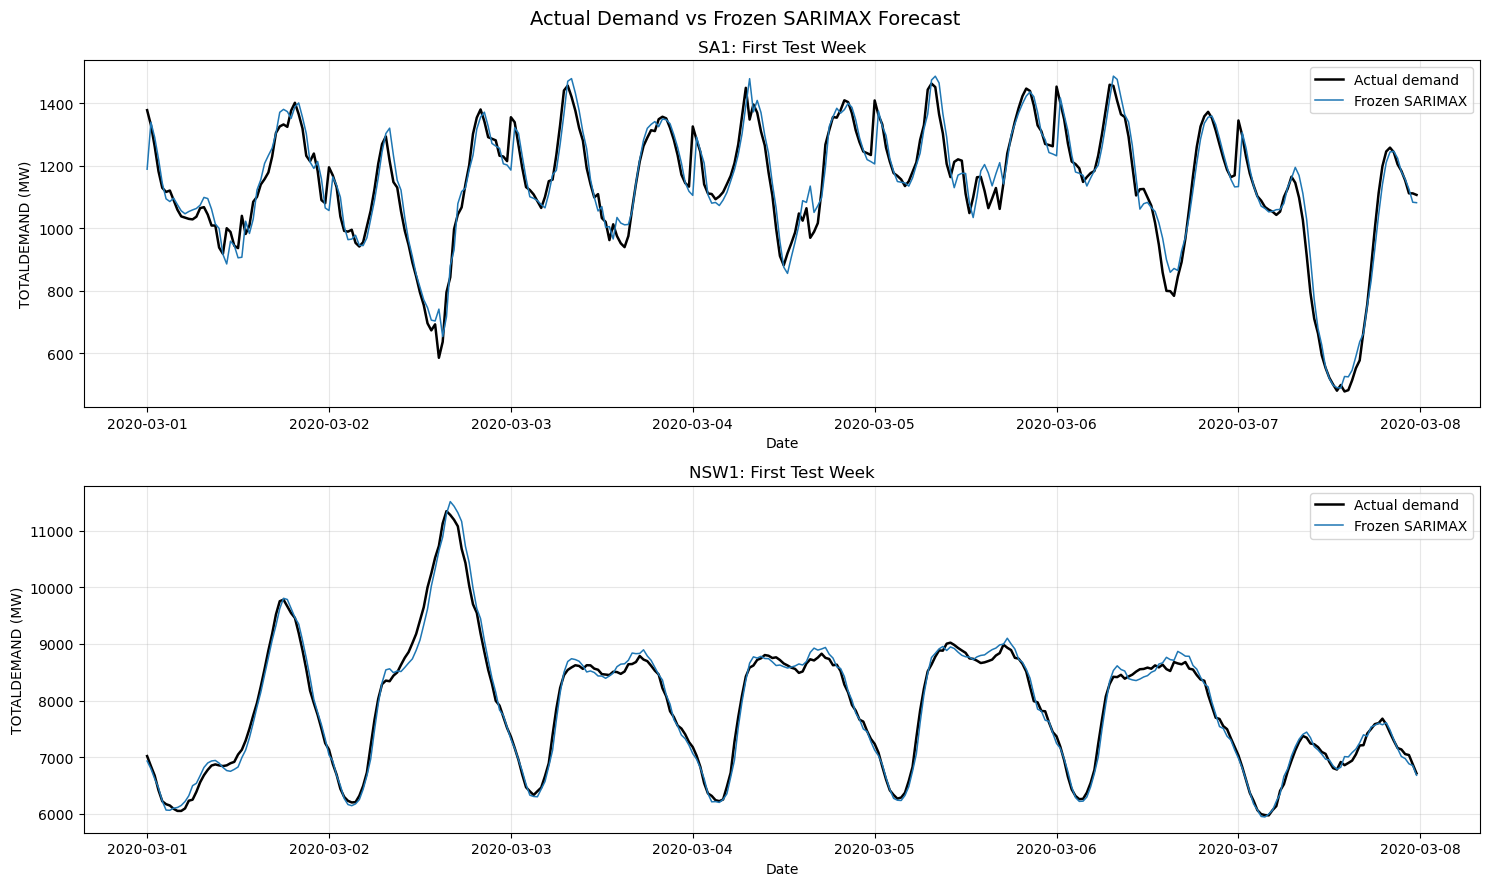

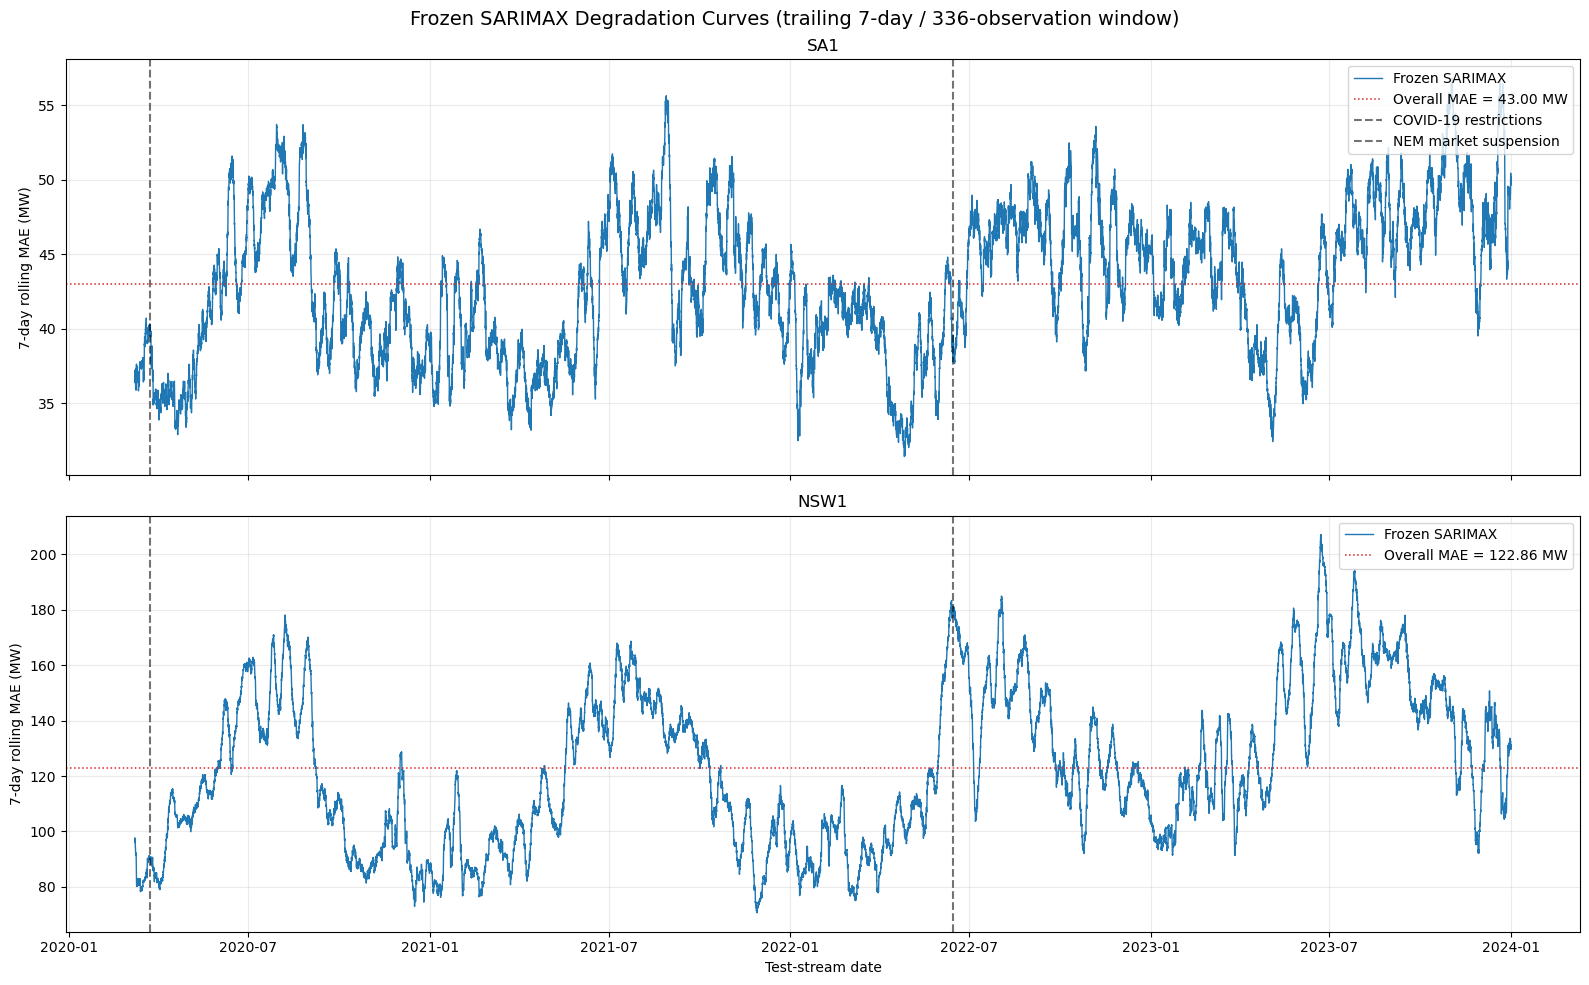

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for axis, region_name in zip(axes, REGIONS):
    first_week = sarimax_results[region_name].head(ROLLING_WINDOW)
    axis.plot(
        first_week[TIME_COLUMN], first_week[TARGET_COLUMN],
        label="Actual demand", linewidth=1.8, color="black"
    )
    axis.plot(
        first_week[TIME_COLUMN], first_week["prediction"],
        label="Frozen SARIMAX", linewidth=1.1, color="tab:blue"
    )
    axis.set_title(f"{region_name}: First Test Week")
    axis.set_xlabel("Date")
    axis.set_ylabel("TOTALDEMAND (MW)")
    axis.grid(alpha=0.3)
    axis.legend()
fig.suptitle("Actual Demand vs Frozen SARIMAX Forecast", fontsize=14)
fig.tight_layout()
forecast_file = figure_path / "sarimax_forecast_first_week.png"
fig.savefig(forecast_file, dpi=180, bbox_inches="tight")
plt.show()


documented_events = {
    "COVID-19 restrictions": pd.Timestamp("2020-03-23"),
    "NEM market suspension": pd.Timestamp("2022-06-15"),
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
for axis, region_name in zip(axes, REGIONS):
    results = sarimax_results[region_name]
    axis.plot(
        results[TIME_COLUMN], results["rolling_mae_7d"],
        label="Frozen SARIMAX", linewidth=1.0, color="tab:blue"
    )
    overall_mae = float(results["absolute_error"].mean())
    axis.axhline(
        overall_mae, color="tab:red", linestyle=":", linewidth=1.1,
        label=f"Overall MAE = {overall_mae:.2f} MW"
    )
    for event_name, event_date in documented_events.items():
        axis.axvline(
            event_date, color="black", linestyle="--", alpha=0.55,
            label=event_name if region_name == "SA1" else None
        )
    axis.set_title(region_name)
    axis.set_ylabel("7-day rolling MAE (MW)")
    axis.grid(alpha=0.25)
    axis.legend(loc="upper right")
axes[-1].set_xlabel("Test-stream date")
fig.suptitle(
    "Frozen SARIMAX Degradation Curves "
    "(trailing 7-day / 336-observation window)", fontsize=14
)
fig.tight_layout()
degradation_file = figure_path / "sarimax_degradation_curve.png"
fig.savefig(degradation_file, dpi=180, bbox_inches="tight")
plt.show()


## Detector-Compatible Error Streams and Saved Results

Only SARIMAX artifacts are written by this notebook. Seasonal-naive and gradient-boosted results can be combined later by the team for the final multi-baseline comparison.


In [29]:
sarimax_error_streams = {}
prediction_frames = []

for region_name in REGIONS:
    results = sarimax_results[region_name]
    stream = results["error"].to_numpy()
    validate_detector_stream(stream, f"{region_name} SARIMAX")
    sarimax_error_streams[region_name] = stream

    output = results.copy()
    output.insert(0, "region", region_name)
    output.insert(1, "model", "sarimax")
    prediction_frames.append(output)

sarimax_predictions = pd.concat(prediction_frames, ignore_index=True)
predictions_file = prediction_path / "sarimax_predictions.csv"
metrics_file = model_path / "sarimax_metrics.csv"
configuration_file = model_path / "sarimax_configuration.csv"

sarimax_predictions.to_csv(predictions_file, index=False)
sarimax_metrics.to_csv(metrics_file, index=False)
sarimax_configuration.to_csv(configuration_file, index=False)

#print("Saved predictions:", predictions_file)
#print("Saved metrics:", metrics_file)
#print("Saved SARIMAX configuration:", configuration_file)
#print("Saved forecast figure:", forecast_file)
#print("Saved degradation curve:", degradation_file)


SA1 SARIMAX detector stream passed: length=67,249, dimensions=1, dtype=float64.
NSW1 SARIMAX detector stream passed: length=67,249, dimensions=1, dtype=float64.


## Initial Findings

The frozen SARIMAX classical baseline was fitted using only the fixed 2018–2019 training data and evaluated chronologically on the fixed test stream from March 2020 to January 2024. The model uses an AR(1) error structure with deterministic daily, weekly and annual Fourier features and a weekend indicator. Train-only standardisation was applied, and the fitted parameters remained frozen during Calibration and Test.


In [26]:
for region_name in REGIONS:
    row = sarimax_metrics.loc[
        sarimax_metrics["region"] == region_name
    ].iloc[0]
    converged = bool(
        sarimax_configuration.loc[
            sarimax_configuration["region"] == region_name,
            "converged"
        ].iloc[0]
    )

    print(f"{region_name} SARIMAX initial findings")
    print(f"- Test observations: {int(row['test_observations']):,}")
    print(f"- MAE: {row['mae_mw']:.2f} MW")
    print(f"- RMSE: {row['rmse_mw']:.2f} MW")
    print(f"- MAPE: {row['mape_percent']:.2f}%")
    print(f"- Missing predictions: {int(row['missing_predictions'])}")
    print(f"- Test-stream retrains: {int(row['test_stream_retrains'])}")
    print(f"- Converged: {converged}")
    print()

print("Frozen-parameter audit: passed for SA1 and NSW1.")
print("Rolling-MAE window: 336 half-hourly observations (7 days).")
print("Error streams: chronological, numeric, one-dimensional and complete.")
print(
    "Rolling-MAE variation shows that forecast performance changes over "
    "time, but it does not by itself prove concept drift."
)


SA1 SARIMAX initial findings
- Test observations: 67,249
- MAE: 43.00 MW
- RMSE: 60.82 MW
- MAPE: 4.07%
- Missing predictions: 0
- Test-stream retrains: 0
- Converged: True

NSW1 SARIMAX initial findings
- Test observations: 67,249
- MAE: 122.86 MW
- RMSE: 172.41 MW
- MAPE: 1.61%
- Missing predictions: 0
- Test-stream retrains: 0
- Converged: True

Frozen-parameter audit: passed for SA1 and NSW1.
Rolling-MAE window: 336 half-hourly observations (7 days).
Error streams: chronological, numeric, one-dimensional and complete.
Rolling-MAE variation shows that forecast performance changes over time, but it does not by itself prove concept drift.


### Key observations from the completed run

- SA1: **MAE 43.00 MW**, **RMSE 60.82 MW**, **MAPE 4.07%**.
- NSW1: **MAE 122.86 MW**, **RMSE 172.41 MW**, **MAPE 1.61%**.
- Both models converged and produced all **67,249** Test predictions with no missing values and no Test-stream retraining.
- The frozen-parameter audit passed for both regions.
- Periods of elevated rolling MAE require formal drift detection and event-based analysis before being attributed to concept drift.
